In [1]:
import os
from google.colab import userdata

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

print("✅ Kaggle API Token connected!")

✅ Kaggle API Token connected!


In [2]:
!kaggle datasets download -d sartajbhuvaji/brain-tumor-classification-mri

Dataset URL: https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri
License(s): MIT
100% 86.8M/86.8M [00:00<00:00, 151MB/s]



In [3]:
import zipfile
import os

# Zip file extract
zip_ref = zipfile.ZipFile('/content/brain-tumor-classification-mri.zip', 'r')
zip_ref.extractall('/content/brain_tumor_dataset')
zip_ref.close()

print("✅ Dataset successfully downloaded and unzipped!")

✅ Dataset successfully downloaded and unzipped!


In [4]:
import tensorflow as tf
from tensorflow import keras

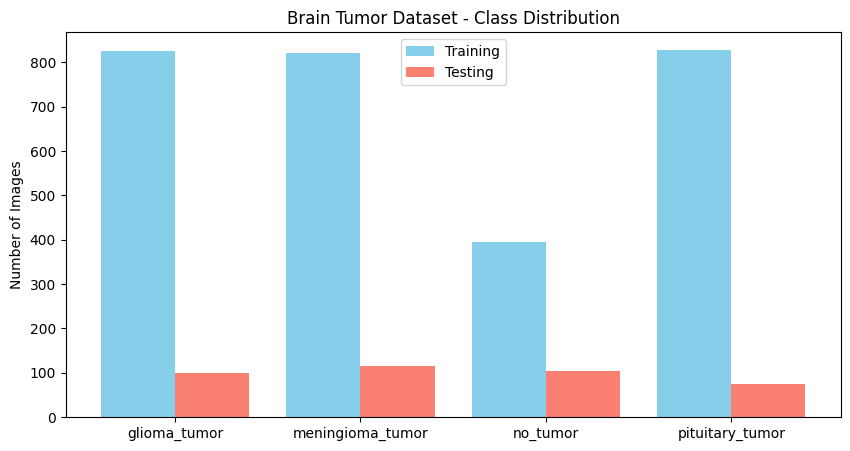

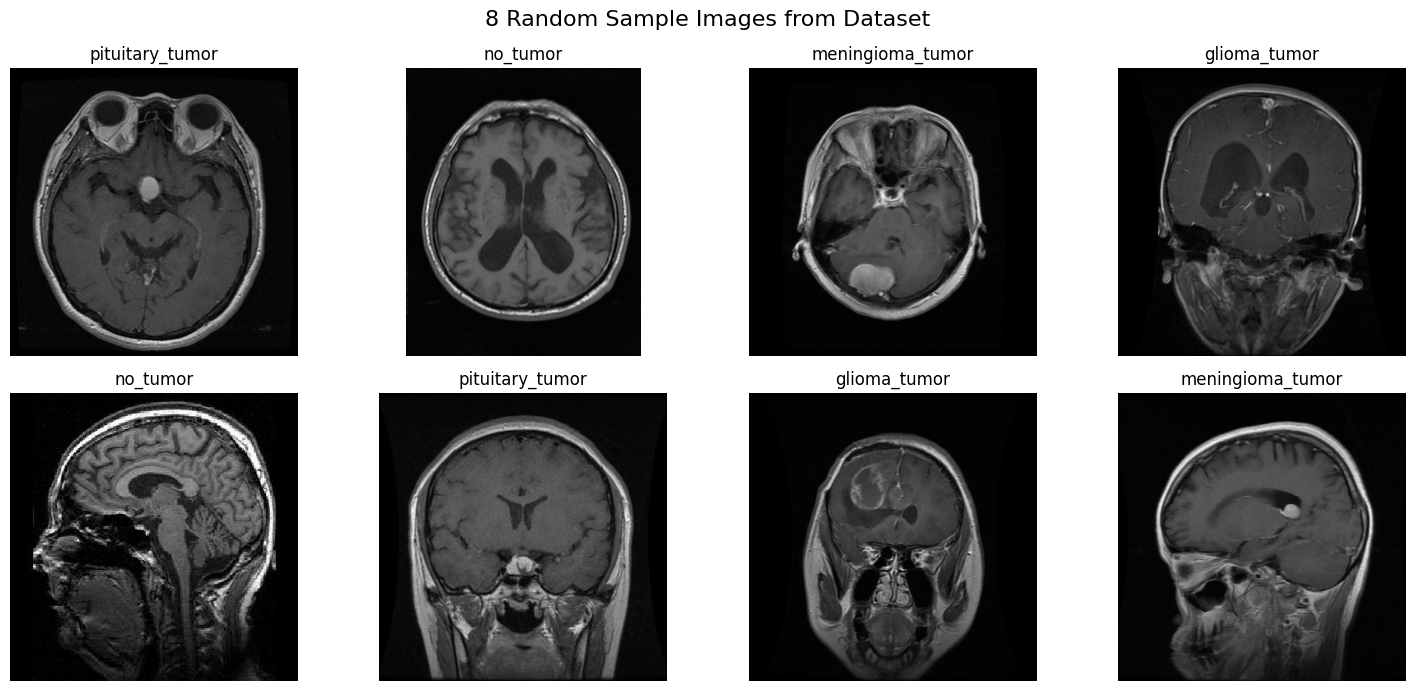

In [5]:
import os
import glob
import hashlib
import random
import shutil
from collections import Counter
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

train_dir = '/content/brain_tumor_dataset/Training'
test_dir = '/content/brain_tumor_dataset/Testing'
classes = sorted(os.listdir(train_dir))

# ==========================================
# 1. CLASS IMBALANCE CHECK (BAR CHART)
# ==========================================
train_counts = [len(os.listdir(os.path.join(train_dir, c))) for c in classes]
test_counts = [len(os.listdir(os.path.join(test_dir, c))) for c in classes]

plt.figure(figsize=(10, 5))
x = range(len(classes))
plt.bar([i - 0.2 for i in x], train_counts, width=0.4, label='Training', color='skyblue')
plt.bar([i + 0.2 for i in x], test_counts, width=0.4, label='Testing', color='salmon')
plt.xticks(x, classes)
plt.ylabel('Number of Images')
plt.title('Brain Tumor Dataset - Class Distribution')
plt.legend()
plt.show()

# ==========================================
# 2. SHOW 8 RANDOM SAMPLE IMAGES
# ==========================================
all_train_images = glob.glob(train_dir + '/*/*')
sample_images = random.sample(all_train_images, 8)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
fig.suptitle("8 Random Sample Images from Dataset", fontsize=16)
for ax, img_path in zip(axes.flatten(), sample_images):
    img = mpimg.imread(img_path)
    ax.imshow(img, cmap='gray')
    label = img_path.split('/')[-2]
    ax.set_title(label)
    ax.axis('off')
plt.tight_layout()
plt.show()

# ==========================================
# 3. DATA LEAKAGE CHECK (MD5 HASHING)
# ==========================================

def get_md5(file_path):
    """Generates an MD5 hash (digital fingerprint) for a given image file."""
    with open(file_path, 'rb') as f:
        file_hash = hashlib.md5()
        while chunk := f.read(8192):
            file_hash.update(chunk)
    return file_hash.hexdigest()

# Create a set of MD5 hashes for all training images
train_hashes = {get_md5(p) for p in glob.glob(train_dir + '/*/*')}


In [ ]:
# ==========================================
# 1. REMOVE DUPLICATES FROM TEST SET & CREATE CLEAN TEST DIRECTORY
# ==========================================
clean_test_dir = '/content/clean_test'
kept, removed = 0, 0

for img_path in glob.glob(test_dir + '/*/*'):
    if get_md5(img_path) in train_hashes:
        removed += 1
        continue 

    # Extract class label and create corresponding directory in clean_test
    cls = img_path.split('/')[-2]
    os.makedirs(f'{clean_test_dir}/{cls}', exist_ok=True)

    # Copy unique image to the clean test directory
    shutil.copy(img_path, f'{clean_test_dir}/{cls}/')
    kept += 1

print(f"Removed exact duplicates from Test: {removed} | Clean test images saved: {kept}")



Removed exact duplicates from Test: 88 | Clean test images saved: 306


In [ ]:

clean_train_dir = '/content/clean_train'
seen = set()
kept_tr, removed_tr = 0, 0

for img_path in sorted(glob.glob(train_dir + '/*/*')):
    h = get_md5(img_path)
    if h in seen:
        removed_tr += 1
        continue
    seen.add(h)
    cls = img_path.split('/')[-2]
    os.makedirs(f'{clean_train_dir}/{cls}', exist_ok=True)
    shutil.copy(img_path, f'{clean_train_dir}/{cls}/')
    kept_tr += 1

print(f"Removed from Training: {removed_tr} | Clean training images: {kept_tr}")

train_ds = keras.utils.image_dataset_from_directory(
    clean_train_dir, validation_split=0.2, subset="training",
    seed=42, label_mode="categorical", image_size=(224, 224), batch_size=32)

val_ds = keras.utils.image_dataset_from_directory(
    clean_train_dir, validation_split=0.2, subset="validation",
    seed=42, label_mode="categorical", image_size=(224, 224), batch_size=32)



Removed from Training: 93 | Clean training images: 2777
Found 2777 files belonging to 4 classes.
Using 2222 files for training.
Found 2777 files belonging to 4 classes.
Using 555 files for validation.


In [8]:
test_ds = keras.utils.image_dataset_from_directory(
    '/content/clean_test', label_mode="categorical",
    image_size=(224, 224), batch_size=32, shuffle=False)

class_names = train_ds.class_names
print(class_names)

Found 306 files belonging to 4 classes.
['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [9]:
from keras import Sequential
from tensorflow.keras import layers
from keras.layers import Dense, Conv2D, MaxPooling2D , Flatten

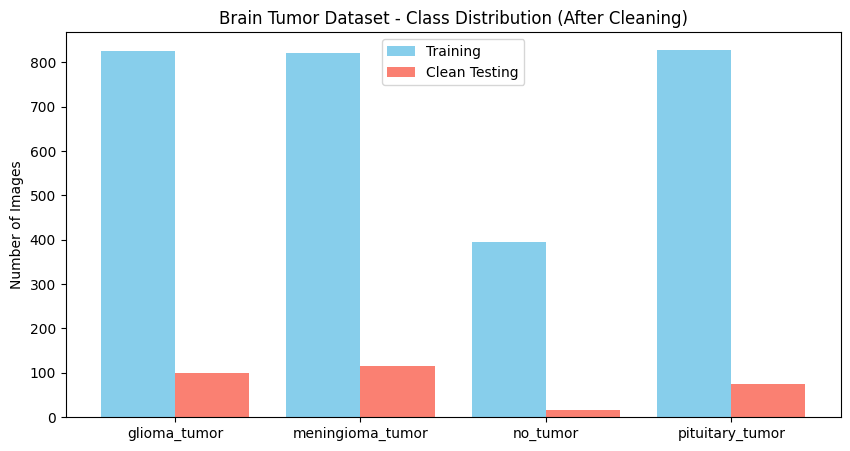

In [10]:
clean_test_dir = '/content/clean_test'
train_dir = '/content/brain_tumor_dataset/Training'

classes = sorted(os.listdir(train_dir))

train_counts = [len(os.listdir(os.path.join(train_dir, c))) for c in classes]
test_counts = [len(os.listdir(os.path.join(clean_test_dir, c))) for c in classes]

plt.figure(figsize=(10, 5))
x = range(len(classes))
plt.bar([i - 0.2 for i in x], train_counts, width=0.4, label='Training', color='skyblue')
plt.bar([i + 0.2 for i in x], test_counts, width=0.4, label='Clean Testing', color='salmon')
plt.xticks(x, classes)
plt.ylabel('Number of Images')
plt.title('Brain Tumor Dataset - Class Distribution (After Cleaning)')
plt.legend()
plt.show()

In [ ]:
import numpy as np
from collections import Counter
from sklearn.metrics import classification_report, confusion_matrix

train_labels = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in train_ds])
counts = Counter(train_labels)
total = len(train_labels)
class_weight = {i: total / (len(counts) * counts[i]) for i in counts}
print("Class weights:", class_weight)

#  Model
base = keras.applications.ResNet50(include_top=False, weights="imagenet",
                                   input_shape=(224, 224, 3))
base.trainable = False

head = keras.Sequential([
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax"),
])

inputs = keras.Input(shape=(224, 224, 3))
x = keras.applications.resnet50.preprocess_input(inputs)
x = base(x, training=False)
outputs = head(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds, epochs=10,
                    callbacks=[early_stop], class_weight=class_weight)

y_true, y_pred = [], []
for xb, yb in val_ds:
    y_true.extend(np.argmax(yb.numpy(), axis=1))
    y_pred.extend(np.argmax(model.predict(xb, verbose=0), axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))
print(confusion_matrix(y_true, y_pred))

Class weights: {np.int64(1): 0.8625776397515528, np.int64(3): 0.8612403100775193, np.int64(0): 0.8303437967115097, np.int64(2): 2.1041666666666665}
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 66s 581ms/step - accuracy: 0.6179 - loss: 0.9090 - val_accuracy: 0.8036 - val_loss: 0.5043
Epoch 2/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 98ms/step - accuracy: 0.7840 - loss: 0.5270 - val_accuracy: 0.8342 - val_loss: 0.4301
Epoch 3/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 93ms/step - accuracy: 0.8294 - loss: 0.4092 - val_accuracy: 0.8541 - val_loss: 0.4187
Epoch 4/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - accuracy: 0.8483 - loss: 0.3669 - val_accuracy: 0.8793 - val_loss: 0.3585
Epoch 5/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 93ms/step - accuracy: 0.8677 - loss: 0.3187 - val_accuracy: 0.8631 - val_loss: 0.3690
Epoch 6/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 98ms/step - accuracy: 0.8641 - loss: 0.3104 - val_accuracy: 0.8559 - val_loss: 0.3749
Epoch 7/10
70/70 ━━━━━━━━━━━━━━━━━━━

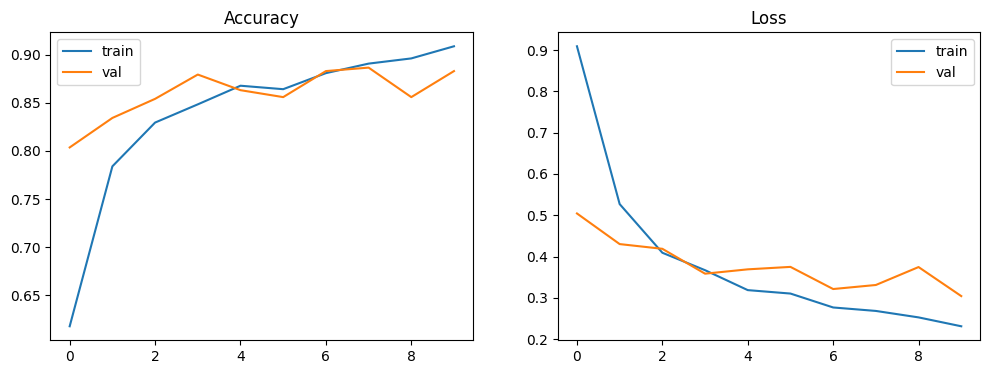

In [12]:
import matplotlib.pyplot as plt

def plot_history(h):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history["accuracy"], label="train")
    ax[0].plot(h.history["val_accuracy"], label="val")
    ax[0].set_title("Accuracy"); ax[0].legend()
    ax[1].plot(h.history["loss"], label="train")
    ax[1].plot(h.history["val_loss"], label="val")
    ax[1].set_title("Loss"); ax[1].legend()
    plt.show()

plot_history(history)

In [13]:
def evaluate_val(model):
    y_true, y_pred = [], []
    for xb, yb in val_ds:
        y_true.extend(np.argmax(yb.numpy(), axis=1))
        y_pred.extend(np.argmax(model.predict(xb, verbose=0), axis=1))
    print(classification_report(y_true, y_pred, target_names=class_names))
    print(confusion_matrix(y_true, y_pred))

Epoch 1/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 52s 380ms/step - accuracy: 0.9077 - loss: 0.2137 - val_accuracy: 0.9081 - val_loss: 0.2814
Epoch 2/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 146ms/step - accuracy: 0.9541 - loss: 0.1285 - val_accuracy: 0.8847 - val_loss: 0.2902
Epoch 3/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 11s 156ms/step - accuracy: 0.9757 - loss: 0.0779 - val_accuracy: 0.9063 - val_loss: 0.2710
Epoch 4/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 146ms/step - accuracy: 0.9829 - loss: 0.0493 - val_accuracy: 0.9153 - val_loss: 0.2587
Epoch 5/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accuracy: 0.9869 - loss: 0.0366 - val_accuracy: 0.9009 - val_loss: 0.2965
Epoch 6/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 134ms/step - accuracy: 0.9946 - loss: 0.0237 - val_accuracy: 0.9297 - val_loss: 0.2738
Epoch 7/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 135ms/step - accuracy: 0.9941 - loss: 0.0197 - val_accuracy: 0.9099 - val_loss: 0.2845


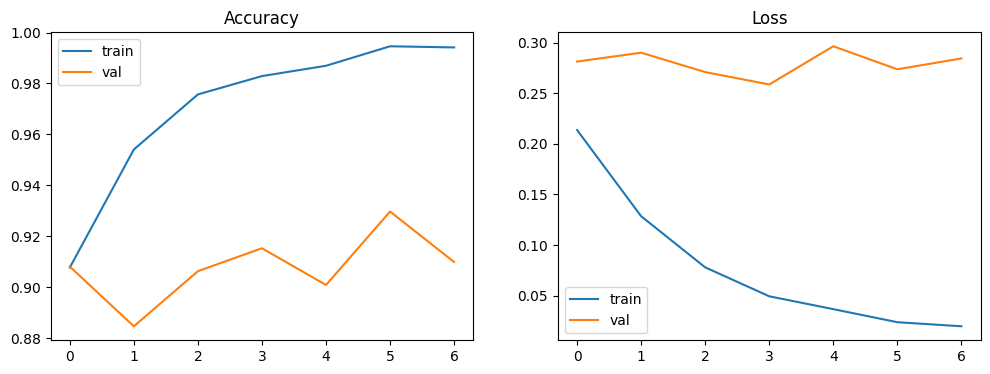

                  precision    recall  f1-score   support

    glioma_tumor       0.91      0.95      0.93       149
meningioma_tumor       0.89      0.84      0.86       170
        no_tumor       0.99      0.94      0.96        71
 pituitary_tumor       0.92      0.95      0.93       165

        accuracy                           0.92       555
       macro avg       0.93      0.92      0.92       555
    weighted avg       0.92      0.92      0.91       555

[[142   7   0   0]
 [ 13 142   1  14]
 [  1   3  67   0]
 [  0   8   0 157]]


In [ ]:

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

early_stop_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=10,
                       callbacks=[early_stop_ft], class_weight=class_weight)

plot_history(history_ft)
evaluate_val(model)

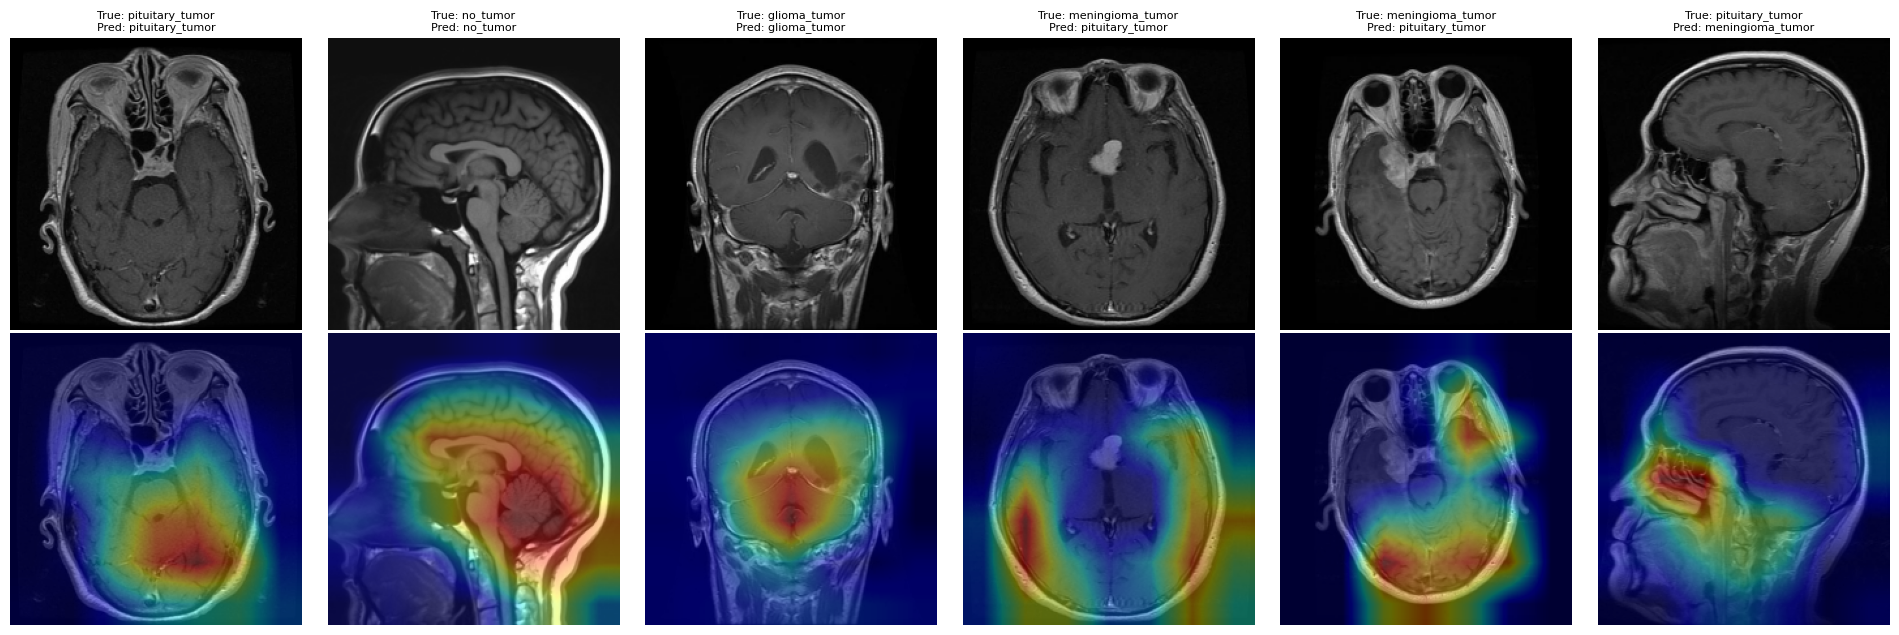

In [ ]:
def grad_cam(img, base, head, class_idx=None):
    x = keras.applications.resnet50.preprocess_input(
        np.expand_dims(img.copy(), 0).astype("float32"))
    conv_model = keras.Model(
        base.input, [base.get_layer("conv5_block3_out").output, base.output])
    with tf.GradientTape() as tape:
        conv_out, feats = conv_model(x)
        preds = head(feats)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0]
    return cam

def show_gradcams(model, base, head, n_each=3):
    imgs, trues, preds = [], [], []
    for xb, yb in val_ds.take(10):
        p = np.argmax(model.predict(xb, verbose=0), axis=1)
        imgs.extend(xb.numpy())
        trues.extend(np.argmax(yb.numpy(), axis=1))
        preds.extend(p)
    correct = [i for i in range(len(imgs)) if trues[i] == preds[i]][:n_each]
    wrong = [i for i in range(len(imgs)) if trues[i] != preds[i]][:n_each]
    chosen = correct + wrong

    fig, axes = plt.subplots(2, len(chosen), figsize=(3.2 * len(chosen), 6.4))
    for col, i in enumerate(chosen):
        cam = grad_cam(imgs[i], base, head)
        axes[0, col].imshow(imgs[i].astype("uint8"))
        axes[0, col].set_title(
            f"True: {class_names[trues[i]]}\nPred: {class_names[preds[i]]}", fontsize=8)
        axes[0, col].axis("off")
        axes[1, col].imshow(imgs[i].astype("uint8"))
        axes[1, col].imshow(cam, cmap="jet", alpha=0.4)
        axes[1, col].axis("off")
    plt.tight_layout()
    plt.savefig("gradcam.png", dpi=150)
    plt.show()

show_gradcams(model, base, head)

Epoch 1/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 36s 263ms/step - accuracy: 0.6121 - loss: 0.9150 - val_accuracy: 0.7658 - val_loss: 0.6029
Epoch 2/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 13s 189ms/step - accuracy: 0.7745 - loss: 0.5677 - val_accuracy: 0.8072 - val_loss: 0.4829
Epoch 3/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 13s 181ms/step - accuracy: 0.8096 - loss: 0.4843 - val_accuracy: 0.7838 - val_loss: 0.5270
Epoch 4/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 12s 178ms/step - accuracy: 0.8321 - loss: 0.4145 - val_accuracy: 0.8613 - val_loss: 0.3812
Epoch 5/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 12s 175ms/step - accuracy: 0.8357 - loss: 0.3941 - val_accuracy: 0.8234 - val_loss: 0.4328
Epoch 6/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 21s 176ms/step - accuracy: 0.8578 - loss: 0.3483 - val_accuracy: 0.8468 - val_loss: 0.4236
Epoch 7/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 13s 182ms/step - accuracy: 0.8519 - loss: 0.3641 - val_accuracy: 0.8360 - val_loss: 0.4253
Epoch 1/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 30s 264ms/step - accuracy: 0.8587 - loss: 0.3603 - val_accu

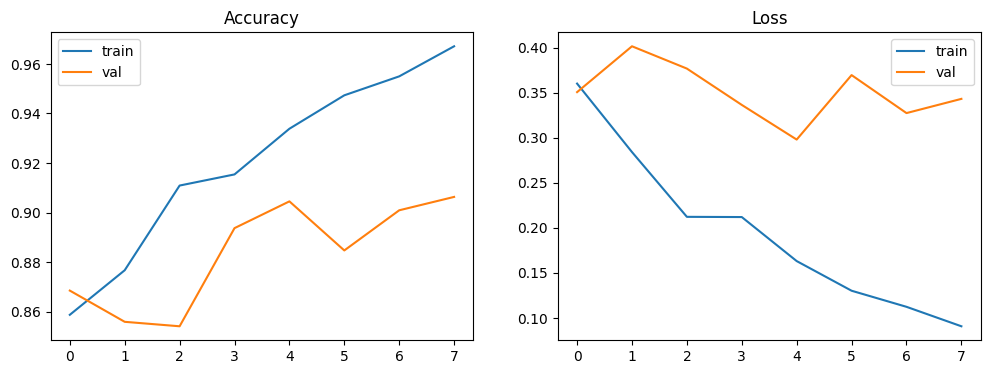

                  precision    recall  f1-score   support

    glioma_tumor       0.90      0.95      0.93       149
meningioma_tumor       0.91      0.79      0.84       170
        no_tumor       0.96      0.96      0.96        71
 pituitary_tumor       0.89      0.96      0.92       165

        accuracy                           0.90       555
       macro avg       0.91      0.91      0.91       555
    weighted avg       0.91      0.90      0.90       555

[[142   6   0   1]
 [ 14 134   3  19]
 [  1   2  68   0]
 [  1   6   0 158]]


In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])

def train_two_stage(use_aug):
    base_ = keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    base_.trainable = False
    head_ = keras.Sequential([
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(4, activation="softmax"),
    ])
    inputs = keras.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs) if use_aug else inputs
    x = keras.applications.resnet50.preprocess_input(x)
    x = base_(x, training=False)
    m = keras.Model(inputs, head_(x))

    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
    es1 = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)
    m.fit(train_ds, validation_data=val_ds, epochs=10,
          callbacks=[es1], class_weight=class_weight)

    base_.trainable = True
    for layer in base_.layers[:-30]:
        layer.trainable = False
    for layer in base_.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    m.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
    es2 = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)
    h2 = m.fit(train_ds, validation_data=val_ds, epochs=10,
               callbacks=[es2], class_weight=class_weight)
    return m, base_, head_, h2

model_aug, base_aug, head_aug, history_aug = train_two_stage(use_aug=True)
plot_history(history_aug)
evaluate_val(model_aug)

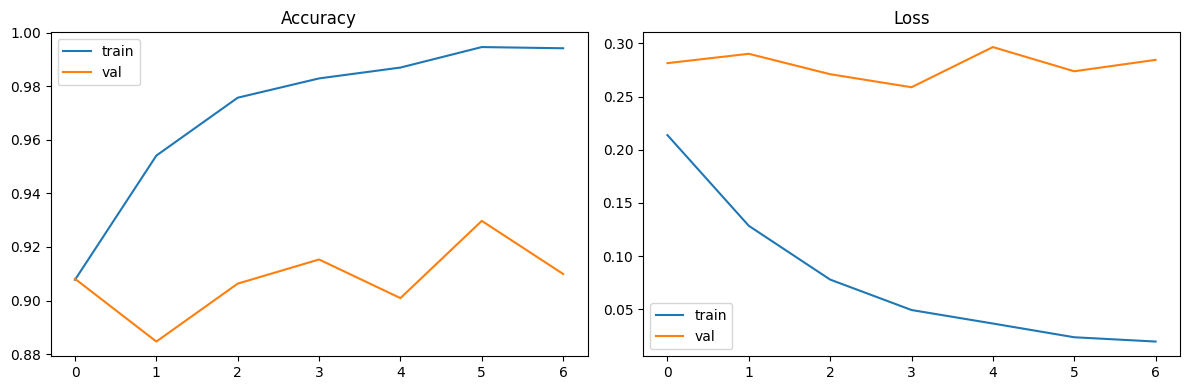

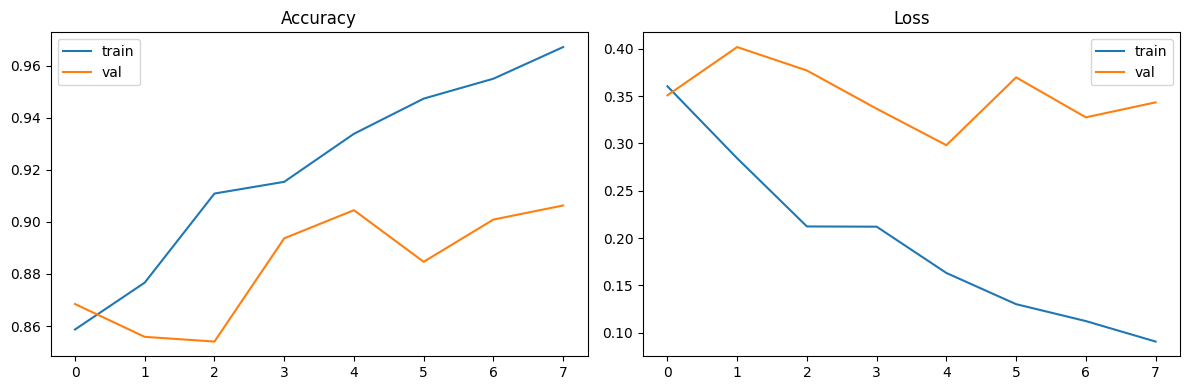

In [19]:
def plot_history(h, filename=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history["accuracy"], label="train")
    ax[0].plot(h.history["val_accuracy"], label="val")
    ax[0].set_title("Accuracy"); ax[0].legend()
    ax[1].plot(h.history["loss"], label="train")
    ax[1].plot(h.history["val_loss"], label="val")
    ax[1].set_title("Loss"); ax[1].legend()
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=150)
    plt.show()

plot_history(history_ft, "curves_finetuned.png")
plot_history(history_aug, "curves_augmentation.png")

In [20]:
def evaluate_ds(model, ds):
    y_true, y_pred = [], []
    for xb, yb in ds:
        y_true.extend(np.argmax(yb.numpy(), axis=1))
        y_pred.extend(np.argmax(model.predict(xb, verbose=0), axis=1))
    print(classification_report(y_true, y_pred, target_names=class_names))
    print(confusion_matrix(y_true, y_pred))

evaluate_ds(model, test_ds)

                  precision    recall  f1-score   support

    glioma_tumor       0.96      0.26      0.41       100
meningioma_tumor       0.63      0.97      0.76       115
        no_tumor       0.37      1.00      0.54        17
 pituitary_tumor       0.98      0.72      0.83        74

        accuracy                           0.68       306
       macro avg       0.73      0.74      0.63       306
    weighted avg       0.81      0.68      0.65       306

[[ 26  53  20   1]
 [  1 112   2   0]
 [  0   0  17   0]
 [  0  14   7  53]]


In [21]:
evaluate_ds(model, val_ds)

                  precision    recall  f1-score   support

    glioma_tumor       0.91      0.95      0.93       149
meningioma_tumor       0.89      0.84      0.86       170
        no_tumor       0.99      0.94      0.96        71
 pituitary_tumor       0.92      0.95      0.93       165

        accuracy                           0.92       555
       macro avg       0.93      0.92      0.92       555
    weighted avg       0.92      0.92      0.91       555

[[142   7   0   0]
 [ 13 142   1  14]
 [  1   3  67   0]
 [  0   8   0 157]]


In [22]:
model.save("/content/drive/MyDrive/baseline_resnet50.keras")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def save_confusion_matrix(model, ds, title, filename):
    y_true, y_pred = [], []
    for xb, yb in ds:
        y_true.extend(np.argmax(yb.numpy(), axis=1))
        y_pred.extend(np.argmax(model.predict(xb, verbose=0), axis=1))
    cm = confusion_matrix(y_true, y_pred)
    print(cm)   

    fig, ax = plt.subplots(figsize=(7, 6))
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=30, colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)   
    plt.show()

save_confusion_matrix(model, val_ds, "Validation (555 images)", "cm_validation.png")
save_confusion_matrix(model, test_ds, "Clean test (306 images)", "cm_test.png")